# Baseline Churn Model Check + Initial Behavioral Drift Score

Input: `data/features_and_label.parquet` (customer-month rows from notebook 03, label `is_churn`)

Output: drift features + `drift_score` per customer-month

1. Verify that the baseline churn models from 06 beat trivial baselines and are not fooled by leakage
2. Build the first behavioral-drift score and test whether it carries churn signal beyond th existing features


## 1. Setup + Load Data

In [20]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

In [21]:
DATA_PATH     = Path('../data/features_and_label.parquet')
OUT_PATH      = Path('../data/drift_scores.parquet')
TARGET        = 'is_churn'

TEST_FRACTION = 0.20   # same as notebook 06: latest 20% of distinct months are the test set

PURGE_MONTHS  = 3      # = the 90-day label window (~3 months)

K_BASELINE    = 3      # a customer's "normal" = mean of their previous 3 ACTIVE months
CLIP_Z        = 3.0    # cap each standardized drift component at +/-3 so one freak month can't dominate
RANDOM_STATE  = 42

In [22]:
df = pd.read_parquet(DATA_PATH)

# CustomerMonth is stored as a Period[M], so we'll convert to a month-start timestamp (same handling as notebook 06)
cm = df['CustomerMonth']
df['CustomerMonth'] = cm.dt.to_timestamp() if isinstance(cm.dtype, pd.PeriodDtype) else pd.to_datetime(cm)

df = df.dropna(subset=[TARGET, 'CustomerMonth']).copy()
df[TARGET] = df[TARGET].astype(int)
df['is_first_month'] = df['is_first_month'].astype(int)   # bool -> 0/1 so every model treats it as a plain number

# sort by customer then month
# all "previous months" logic below (shift/rolling) depends on this order
df = df.sort_values(['Customer ID', 'CustomerMonth']).reset_index(drop=True)

print(f'Rows: {len(df):,} | customers: {df["Customer ID"].nunique():,} | churn rate: {df[TARGET].mean():.2%}')
print(f'Months: {df.CustomerMonth.min():%Y-%m} to {df.CustomerMonth.max():%Y-%m}')
display(df.head())

Rows: 20,880 | customers: 5,248 | churn rate: 38.99%
Months: 2009-12 to 2011-09


,Customer ID,CustomerMonth,purchase_frequency,total_spend,avg_order_value,unique_items,days_since_last_purchase,is_first_month,is_churn
0,12346,2010-03-01,1,27.05,27.05,5,NaN,1,1
1,12346,2010-06-01,1,142.31,142.31,19,118.0,0,1
2,12346,2011-01-01,1,149.76,149.76,1,203.0,0,1
3,12347,2010-10-01,1,611.53,611.53,40,NaN,1,0
4,12347,2010-12-01,1,711.79,711.79,31,37.0,0,0


## 2. Chronological Split with a Purge Gap

Same idea as notebook 06: train on earlier months & test on the latest 20% of distinct months. A random split would be wrong here, because it lets the model learn from the future.

- Added a purge gap of 3 months at the end of train

A training row from month *M* is labeled using purchases up to ~90 days after its last purchase, which reaches into months *M+1 ... M+3*. 

If the test period starts right after train, the final training labels are partly built from purchases that fall *inside the test period*, so the model has indirectly seen test-period behavior. 

Dropping the last `PURGE_MONTHS` months of train removes that overlap.

The cost is a smaller training set; the benefit is a test score that reflects what you'd get in production.


In [23]:
def make_split(data, purge_months):
    months = np.sort(data['CustomerMonth'].unique())
    cutoff_idx = min(max(1, int(np.floor(len(months) * (1 - TEST_FRACTION)))), len(months) - 1)
    cutoff = pd.Timestamp(months[cutoff_idx])
    train_end = cutoff - pd.DateOffset(months=purge_months)   # train uses months strictly before this
    train = data[data['CustomerMonth'] < train_end]
    test  = data[data['CustomerMonth'] >= cutoff]
    return train, test, cutoff, train_end

train_df, test_df, cutoff, train_end = make_split(df, PURGE_MONTHS)
train_nopurge, _, _, _ = make_split(df, 0)

print(f'Test starts:               {cutoff:%Y-%m}')
print(f'Purged train ends before:  {train_end:%Y-%m}  -> {len(train_df):,} rows, churn {train_df[TARGET].mean():.2%}')
print(f'Un-purged train (as in 06): {len(train_nopurge):,} rows')
print(f'Test:                      {len(test_df):,} rows, churn {test_df[TARGET].mean():.2%}')
assert train_df['CustomerMonth'].max() < test_df['CustomerMonth'].min(), 'train must precede test'

Test starts:               2011-05
Purged train ends before:  2011-02  -> 14,103 rows, churn 40.19%
Un-purged train (as in 06): 16,686 rows
Test:                      4,194 rows, churn 35.24%


## 3. Checking the Baseline Models Work

Using same three models and hyperparameters as notebook 06 (logistic regression, random forest, XGBoost), so results are comparable.

Headline metrics are ROC AUC, PR AUC, and lift in the top 10%

All three are threshold-free.

The models use `class_weight='balanced'` / `scale_pos_weight`, which shifts predicted probabilities so that the default 0.5 cutoff is arbitrary, and precision/recall/F1 at 0.5 mostly reflect that choice rather than model quality. 

Lift at 10% answers the business question "if we contact the 10% of customers the model ranks riskiest, how many more churners do we catch than by picking at random?"

In [24]:
BASE_FEATURES = ['purchase_frequency', 'total_spend', 'avg_order_value',
                 'unique_items', 'days_since_last_purchase', 'is_first_month']

def lift_at(y, score, frac=0.10):
    # churn rate among the top `frac` highest-scored rows, divided by the overall churn rate
    # Ties (e.g. a constant dummy score, or the many neutral-0 drift rows) are broken randomly with a fixed seed
    # Without this, tied rows would be ranked by row order and a constant score could show a fake lift
    y = np.asarray(y); score = np.asarray(score); k = max(1, int(len(y) * frac))
    order = np.random.default_rng(RANDOM_STATE).permutation(len(y))
    top = order[np.argsort(-score[order], kind='stable')[:k]]
    return y[top].mean() / y.mean()

def score_metrics(y, s):
    return {'ROC AUC': roc_auc_score(y, s), 'PR AUC': average_precision_score(y, s), 'Lift@10%': lift_at(y, s)}

def build_models(y_train):
    # same hyperparameters from notebook 06 on purpose (comparability)
    # Median imputation is only
    # needed for days_since_last_purchase in first-month rows; 
    # is_first_month tells the model which rows were imputed.
    return {
        'Logistic regression': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
            LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE)),
        'Random forest': make_pipeline(SimpleImputer(strategy='median'),
            RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1)),
        'XGBoost': make_pipeline(SimpleImputer(strategy='median'),
            XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                          scale_pos_weight=(y_train == 0).sum() / max((y_train == 1).sum(), 1),
                          eval_metric='logloss', random_state=RANDOM_STATE, n_jobs=-1)),
    }

def fit_and_eval(tr, te, features):
    models = build_models(tr[TARGET])
    rows, fitted = {}, {}
    for name, m in models.items():
        m.fit(tr[features], tr[TARGET])
        p_te = m.predict_proba(te[features])[:, 1]
        p_tr = m.predict_proba(tr[features])[:, 1]
        rows[name] = {**score_metrics(te[TARGET], p_te), 'Train ROC AUC': roc_auc_score(tr[TARGET], p_tr)}
        fitted[name] = m
    return pd.DataFrame(rows).T, fitted


## results
results_purged, fitted_base = fit_and_eval(train_df, test_df, BASE_FEATURES)
print(f'Test churn rate (= PR AUC of a random model): {test_df[TARGET].mean():.3f}')
display(results_purged.round(3))

Test churn rate (= PR AUC of a random model): 0.352


,ROC AUC,PR AUC,Lift@10%,Train ROC AUC
Logistic regression,0.766,0.626,2.066,0.734
Random forest,0.713,0.533,1.734,1.000
XGBoost,0.765,0.604,2.025,0.804


### Sanity Checks

1. **Trivial baselines** A model that predicts the class prior should score ROC AUC ~0.5 and PR AUC ~ churn rate. A single raw column (recency) is the "simple rule" every real model must beat
2. **Shuffled-label test** Train on randomly permuted labels and score on the real test labels; the *average* AUC over many shuffles should be ~0.5. This is a coarse plumbing check (it would catch, for example, test rows accidentally ending up in train). It cannot detect leakage inside the features, which is what the purge and the drift truncation test below address
3. **Train-vs-test gap** A huge gap (for example train AUC ~1.0) means overfitting
4. **Purge effect** Compare the unpurged split of notebook 06 against the purged split
5. **Stability by month** One good test month can hide a bad one

### 1. Trivial Baselines
The real models should clearly beat the dummy and the recency rule on ROC AUC and PR AUC, and have Lift@10% above 1

In [25]:
dummy = DummyClassifier(strategy='prior').fit(train_df[BASE_FEATURES], train_df[TARGET])
dummy_s = dummy.predict_proba(test_df[BASE_FEATURES])[:, 1]

# single-feature rule: raw days_since_last_purchase (first-month NaN -> train median)
# not sign-flipped, so an AUC below 0.5 would mean longer gaps actually go with LESS churn here
rec = test_df['days_since_last_purchase'].fillna(train_df['days_since_last_purchase'].median())

dummy_metrics = score_metrics(test_df[TARGET], dummy_s)
# a constant score ranks nobody, so its Lift@10% is a pure coin-flip
# One random draw is noisy (+/-~13% at this test size), 
# so report the AVERAGE over many random rankings instead; it should land at ~1.0 by construction
rs = np.random.default_rng(RANDOM_STATE)
dummy_metrics['Lift@10%'] = np.mean([lift_at(test_df[TARGET], rs.random(len(test_df))) for _ in range(300)])

baselines = pd.DataFrame({
    'Dummy (class prior)':       dummy_metrics,
    'Rule: recency only':        score_metrics(test_df[TARGET], rec),
}).T
display(pd.concat([baselines, results_purged[['ROC AUC', 'PR AUC', 'Lift@10%']]]).round(3))


,ROC AUC,PR AUC,Lift@10%
Dummy (class prior),0.500,0.352,1.001
Rule: recency only,0.715,0.582,1.991
Logistic regression,0.766,0.626,2.066
Random forest,0.713,0.533,1.734
XGBoost,0.765,0.604,2.025


### 2. Shuffled-Label Test
A shuffled-label *mean* AUC far from 0.5 (say outside 0.45-0.55) means a plumbing bug

Individual shuffles can land well away from 0.5; that is expected

In [26]:
# each run trains on pure-noise labels and is scored on the REAL test labels
# single runs vary a lot (a noise-trained model has random weights over features that are individually predictive, 
# so its AUC lands above OR below 0.5)
# so judge the MEAN over many shuffles, not any one run
rng = np.random.default_rng(RANDOM_STATE)
shuf = []
for _ in range(20):
    y_shuf = pd.Series(rng.permutation(train_df[TARGET].values), index=train_df.index)
    m = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                      LogisticRegression(max_iter=2000, class_weight='balanced'))
    m.fit(train_df[BASE_FEATURES], y_shuf)
    shuf.append(roc_auc_score(test_df[TARGET], m.predict_proba(test_df[BASE_FEATURES])[:, 1]))
print(f'Shuffled-label ROC AUC over {len(shuf)} shuffles: mean {np.mean(shuf):.3f}, std {np.std(shuf):.3f}, range {min(shuf):.3f} to {max(shuf):.3f}   (expect mean ~0.5)')


Shuffled-label ROC AUC over 20 shuffles: mean 0.536, std 0.152, range 0.265 to 0.737   (expect mean ~0.5)


### 3. Train-vs-Test Gap
A very large Train-minus-Test gap (random forest with unlimited depth usually shows ~1.0 train AUC) means the model is memorizing. 

In [27]:
gap = (results_purged['Train ROC AUC'] - results_purged['ROC AUC']).rename('Train - Test AUC')
display(gap.round(3).to_frame())

,Train - Test AUC
Logistic regression,-0.032
Random forest,0.287
XGBoost,0.039


### 4. Effect of the Purge Gap
If the purged AUC is noticeably lower than the un-purged AUC, notebook 06 was slightly optimistic and the purged number is the one to report

* With the un-purged split, some training labels were built from purchases that happen in the test period. The model has indirectly seen a bit of the answer, so its test score is inflated. The model itself isn’t better

In [28]:
res_nopurge, _ = fit_and_eval(train_nopurge, test_df, BASE_FEATURES)
purge_cmp = pd.DataFrame({'ROC AUC (no purge, notebook 06)': res_nopurge['ROC AUC'],
                          'ROC AUC (purged)':             results_purged['ROC AUC']})
purge_cmp['Difference'] = purge_cmp.iloc[:, 0] - purge_cmp.iloc[:, 1]
display(purge_cmp.round(3))

# no purge is yields higher scores

,"ROC AUC (no purge, notebook 06)",ROC AUC (purged),Difference
Logistic regression,0.766,0.766,-0.000
Random forest,0.719,0.713,0.006
XGBoost,0.768,0.765,0.003


### 5. Stability by Test Month
Because `total_spend` and `avg_order_value` are identical on most rows, logistic-regression coefficients for the two are not individually interpretable (they split one signal)

Tree models are unaffected.

In [29]:
per_month = {}
for name in ['Logistic regression', 'XGBoost']:
    p = pd.Series(fitted_base[name].predict_proba(test_df[BASE_FEATURES])[:, 1], index=test_df.index)
    per_month[name] = {
        f'{mth:%Y-%m}': (roc_auc_score(g[TARGET], p.loc[g.index]) if g[TARGET].nunique() == 2 else np.nan)
        for mth, g in test_df.groupby('CustomerMonth')}
display(pd.DataFrame(per_month).T.round(3))


,2011-05,2011-06,2011-07,2011-08,2011-09
Logistic regression,0.791,0.771,0.757,0.750,0.714
XGBoost,0.791,0.771,0.751,0.753,0.719


### Understanding
Positive value: a higher value of that feature goes with more churn

Negative value: a higher value goes with less churn

Size: because everything is on the same scale, we can compare magnitudes across features

The table is sorted from most protective (top) to most churn-linked (bottom)


| Feature | Expected sign | Reasoning |
|---|---|---|
| `purchase_frequency` | negative | buying more often, less churn |
| `total_spend` | negative | bigger spenders are more engaged |
| `unique_items` | negative | broader engagement |
| `days_since_last_purchase` | positive | longer gap, drifting away |
| `is_first_month` | unclear | new customers can go either way |

In [30]:
# logistic regression coefficients: do the signs make business sense? -
coefs = pd.Series(fitted_base['Logistic regression'][-1].coef_[0], index=BASE_FEATURES).sort_values()
display(coefs.round(3).rename('Std. coefficient (+ = more churn)').to_frame())

,Std. coefficient (+ = more churn)
purchase_frequency,-0.526
total_spend,-0.407
unique_items,-0.086
avg_order_value,-0.065
days_since_last_purchase,0.523
is_first_month,0.593


## Behavioral Drift Features

Drift compares each customer-month with that customer's own recent normal

To-Do: 
- Build drift at the customer-month grain
- baseline = mean of the customer's previous `K_BASELINE`=3 *active* months
customer-month rows only exist for months with a purchase, so "previous 3 months" in calendar terms would often be empty

Trade-off: a customer returning after a long silence is compared with their last active months, not with the silent months in between, and that silence is already captured by `days_since_last_purchase`


| Feature | Meaning | "Worse" direction |
|---|---|---|
| `freq_drift` | orders this month vs. normal | negative |
| `spend_drift` | spend this month vs. normal | negative |
| `items_drift` | distinct products vs. normal | negative |
| `aov_drift` | avg order value vs. normal | negative |
| `gap_drift` | days-since-last-purchase vs. the customer's usual gap | **positive** (slower) |
| `n_prior_months` | active months before this one (how much history backs the drift) | N/A |


In [31]:
DRIFT_BASES = { # new feature name : source column in features_and_label
    'freq_drift':  'purchase_frequency',
    'spend_drift': 'total_spend',
    'items_drift': 'unique_items',
    'aov_drift':   'avg_order_value',
}

def trailing_baseline(frame, col, k=K_BASELINE):
    # mean of the customer's previous k rows (active months)
    # shift(1) excludes the current row -> no leakage
    return frame.groupby('Customer ID')[col].transform(lambda s: s.shift(1).rolling(k, min_periods=1).mean())

def compute_drift_raw(frame):
    # returns raw drift columns with NaN kept where no baseline exists 
    # (NaN != 0: it means 'unknown')
    out = pd.DataFrame(index=frame.index)
    for name, col in DRIFT_BASES.items():
        out[name] = np.log1p(frame[col]) - np.log1p(trailing_baseline(frame, col))
    # positive = current gap is longer than the customer's usual gap
    out['gap_drift'] = np.log1p(frame['days_since_last_purchase']) - np.log1p(trailing_baseline(frame, 'days_since_last_purchase'))
    out['n_prior_months'] = frame.groupby('Customer ID').cumcount()
    return out

drift_raw = compute_drift_raw(df)
drift_cols = list(DRIFT_BASES) + ['gap_drift']

print('Share of rows with a computable drift value (the rest are first/second-month rows):')
display(drift_raw[drift_cols].notna().mean().round(3).to_frame('coverage'))
display(drift_raw[drift_cols].describe().round(3))

Share of rows with a computable drift value (the rest are first/second-month rows):


,coverage
freq_drift,0.749
spend_drift,0.749
items_drift,0.749
aov_drift,0.749
gap_drift,0.579


,freq_drift,spend_drift,items_drift,aov_drift,gap_drift
count,15632.000,15632.000,15632.000,15632.000,12099.000
mean,-0.020,-0.133,-0.148,-0.105,-0.075
std,0.270,0.738,0.706,0.658,0.840
min,-1.711,-7.829,-4.538,-5.656,-4.818
25%,-0.154,-0.510,-0.511,-0.431,-0.566
50%,0.000,-0.088,-0.105,-0.059,-0.043
75%,0.000,0.289,0.272,0.264,0.451
max,1.281,4.660,3.314,4.660,3.555


In [32]:
# leakage guard: recompute drift for one customer by hand and compare
# A customer's drift in month M must not change if we delete every later month from the data
cid = df.groupby('Customer ID').size().sort_values().index[-1] # a customer with a long history
sub = df[df['Customer ID'] == cid]
mid = len(sub) // 2
truncated = sub.iloc[:mid + 1] # pretend the data ends at month `mid`
full_val  = drift_raw.loc[sub.index[mid], 'freq_drift']
trunc_val = compute_drift_raw(truncated).loc[truncated.index[mid], 'freq_drift']
print(f'freq_drift at month {mid}: full data {full_val:.6f} | data truncated at that month {trunc_val:.6f}')
assert np.isclose(full_val, trunc_val, equal_nan=True), 'drift uses future information!'
print('OK: drift does not depend on later months')

freq_drift at month 11: full data 0.587787 | data truncated at that month 0.587787
OK: drift does not depend on later months


## 5. Initial Drift Score

**Goal**: collapse the five drift signals into one number per customer-month that is higher when behavior is deteriorating

In [33]:
# component -> sign that makes "higher = worse"
SCORE_COMPONENTS = {'freq_drift': -1, 'spend_drift': -1, 'items_drift': -1, 'gap_drift': +1}

class DriftScorer:
    # fit on TRAIN rows only; apply to any rows
    # keeps standardization free of test information
    def fit(self, raw, fit_idx):
        self.stats = {}
        for c, sign in SCORE_COMPONENTS.items():
            v = (sign * raw.loc[fit_idx, c]).dropna() # only rows where a baseline exists
            self.stats[c] = (v.mean(), v.std(ddof=0) or 1.0)
        return self

    def transform(self, raw):
        comps = pd.DataFrame(index=raw.index)
        for c, sign in SCORE_COMPONENTS.items():
            mu, sd = self.stats[c]
            z = ((sign * raw[c]) - mu) / sd
            comps[c + '_z'] = z.clip(-CLIP_Z, CLIP_Z).fillna(0.0) # unknown -> neutral 0
        score = comps.mean(axis=1).rename('drift_score')
        return comps, score

scorer = DriftScorer().fit(drift_raw, train_df.index)
components, drift_score = scorer.transform(drift_raw)
print('Train-fitted (mean, std) per oriented component:')
display(pd.DataFrame(scorer.stats, index=['mean', 'std']).T.round(3))

Train-fitted (mean, std) per oriented component:


,mean,std
freq_drift,0.009,0.283
spend_drift,0.095,0.748
items_drift,0.129,0.720
gap_drift,-0.140,0.809


### Does the Drift Score Separate Churners from Non-Churners?

In [34]:
test_idx = test_df.index
full_signal = test_idx[drift_raw.loc[test_idx, 'n_prior_months'] >= 2]

def eval_score(idx, s, label):
    return {label: score_metrics(df.loc[idx, TARGET], s.loc[idx])}

rows = {}
rows.update(eval_score(test_idx,    drift_score, 'Drift score (all test rows)'))
rows.update(eval_score(full_signal, drift_score, 'Drift score (>=2 prior months)'))
rows.update({'Recency rule (>=2 prior months)': score_metrics(df.loc[full_signal, TARGET], df.loc[full_signal, 'days_since_last_purchase'].fillna(0))})

print(f'Coverage: {len(full_signal)/len(test_idx):.1%} of test rows have >=2 prior months')
print(f'Churn rate overall {df.loc[test_idx, TARGET].mean():.3f} | in >=2-prior-months rows {df.loc[full_signal, TARGET].mean():.3f}')
display(pd.DataFrame(rows).T.round(3))

# component-level view: which single signal carries the most information?
comp_auc = {c: roc_auc_score(df.loc[full_signal, TARGET], components.loc[full_signal, c]) for c in components.columns}
display(pd.Series(comp_auc, name='ROC AUC (>=2 prior months)').round(3).to_frame())

Coverage: 78.9% of test rows have >=2 prior months
Churn rate overall 0.352 | in >=2-prior-months rows 0.297


,ROC AUC,PR AUC,Lift@10%
Drift score (all test rows),0.557,0.387,1.131
Drift score (>=2 prior months),0.574,0.348,1.315
Recency rule (>=2 prior months),0.745,0.569,2.293


,ROC AUC (>=2 prior months)
freq_drift_z,0.490
spend_drift_z,0.549
items_drift_z,0.566
gap_drift_z,0.575


,rows,churn_rate,mean_score
decile,,,
1,420,0.183,-0.929
2,419,0.313,-0.438
3,419,0.298,-0.228
4,420,0.319,-0.080
5,419,0.539,-0.000
6,419,0.389,0.046
7,420,0.374,0.187
8,419,0.365,0.361
9,419,0.344,0.592


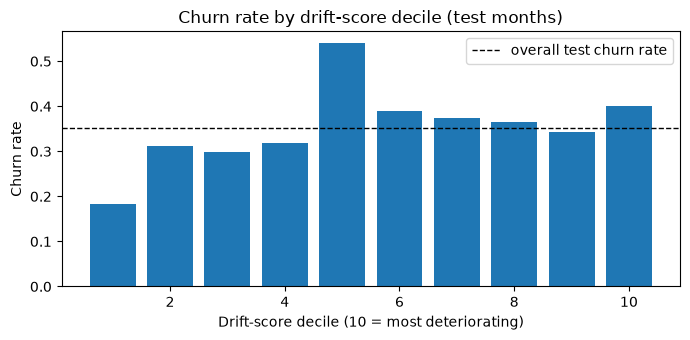

In [35]:
# churn rate by drift-score decile (test rows)
# a usable score shows churn rising from decile 1 to 10
# rank(method='first') breaks the many ties (all the neutral-0 rows) so every decile is the same size
t = pd.DataFrame({'score': drift_score.loc[test_idx], 'churn': df.loc[test_idx, TARGET]})
t['decile'] = pd.qcut(t['score'].rank(method='first'), 10, labels=range(1, 11))
dec = t.groupby('decile', observed=True).agg(rows=('churn', 'size'), churn_rate=('churn', 'mean'), mean_score=('score', 'mean'))
display(dec.round(3))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(dec.index.astype(int), dec['churn_rate'])
ax.axhline(t['churn'].mean(), color='k', ls='--', lw=1, label='overall test churn rate')
ax.set(xlabel='Drift-score decile (10 = most deteriorating)', ylabel='Churn rate', title='Churn rate by drift-score decile (test months)')
ax.legend(); plt.tight_layout(); plt.show()

### Upper Bound: Learned Weights

A logistic regression on the same drift components shows what *weighting* them by the label could add

- If it is only slightly better than the equal-weight score, the simple score is good enough for a first version
- If it is far better, the next iteration should learn weights

In [36]:
sup = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE))
sup.fit(components.loc[train_df.index], train_df[TARGET])
sup_s = pd.Series(sup.predict_proba(components.loc[test_idx])[:, 1], index=test_idx)

cmp = pd.DataFrame({
    'Equal-weight drift score': score_metrics(df.loc[test_idx, TARGET], drift_score.loc[test_idx]),
    'Learned-weight (LR on components)': score_metrics(df.loc[test_idx, TARGET], sup_s),
}).T
display(cmp.round(3))
display(pd.Series(sup[-1].coef_[0], index=components.columns, name='learned weight').round(3).to_frame())

,ROC AUC,PR AUC,Lift@10%
Equal-weight drift score,0.557,0.387,1.131
Learned-weight (LR on components),0.577,0.420,1.300


,learned weight
freq_drift_z,-0.026
spend_drift_z,-0.015
items_drift_z,0.065
gap_drift_z,0.009


## 6. Does Drift Add Value for the Models?

Q: Do the **baseline features + drift** beat the **baseline features alone** on the same purged split, with the same models and hyperparameters? 


In [37]:
MODEL_DRIFT_COLS = list(DRIFT_BASES) + ['gap_drift', 'n_prior_months']
model_df = df.copy()
model_df[MODEL_DRIFT_COLS] = drift_raw[MODEL_DRIFT_COLS].fillna(0.0)   # neutral fill; n_prior_months tells models how much to trust it
model_df['drift_score'] = drift_score

AUG_FEATURES = BASE_FEATURES + MODEL_DRIFT_COLS + ['drift_score']
tr, te = model_df.loc[train_df.index], model_df.loc[test_df.index]

res_base, _      = fit_and_eval(tr, te, BASE_FEATURES)
res_aug, fit_aug = fit_and_eval(tr, te, AUG_FEATURES)

lift_tbl = pd.concat({'Baseline features': res_base[['ROC AUC', 'PR AUC', 'Lift@10%']],
                      'Baseline + drift':  res_aug[['ROC AUC', 'PR AUC', 'Lift@10%']]}, axis=1)
for m in ['ROC AUC', 'PR AUC', 'Lift@10%']:
    lift_tbl[('Change', m)] = lift_tbl[('Baseline + drift', m)] - lift_tbl[('Baseline features', m)]
display(lift_tbl.round(3))

Baseline features                 Baseline + drift         \
                              ROC AUC PR AUC Lift@10%          ROC AUC PR AUC   
Logistic regression             0.766  0.626    2.066            0.796  0.648   
Random forest                   0.713  0.533    1.734            0.762  0.568   
XGBoost                         0.765  0.604    2.025            0.784  0.616   

                              Change                  
                    Lift@10% ROC AUC PR AUC Lift@10%  
Logistic regression    2.154   0.030  0.022    0.088  
Random forest          1.740   0.049  0.035    0.007  
XGBoost                2.011   0.019  0.011   -0.014

In [38]:
# which features does the best tree model lean on? (XGBoost gain-based importance on the augmented set)
imp = pd.Series(fit_aug['XGBoost'][-1].feature_importances_, index=AUG_FEATURES).sort_values(ascending=False)
display(imp.round(3).rename('XGBoost importance').to_frame())

,XGBoost importance
is_first_month,0.250
n_prior_months,0.169
days_since_last_purchase,0.128
purchase_frequency,0.104
total_spend,0.060
gap_drift,0.051
freq_drift,0.043
avg_order_value,0.036
drift_score,0.035
aov_drift,0.032


### NOTE
- A consistent positive change in ROC AUC / PR AUC across all three models means drift carries information the six baseline features don't. A change near zero means the first version of the drift concept doesn't add value yet
- Looking at the *spread across models*: a gain only for XGBoost may just be extra capacity rather than a real signal
- Drift is only defined from the second active month onward, so its power concentrates in repeat customers. One-time buyers (a big share of churners in retail data) get a neutral value by construction

### Where Does the Gain Come From? (One Change at a Time)

The comparison above added two kinds of information at once:
- the **drift columns** (`freq_drift`, `spend_drift`, `items_drift`, `aov_drift`, `gap_drift`, `drift_score`)
- **`n_prior_months`**, how many active months the customer had before this one. This is really a *tenure* feature, not a drift feature

XGBoost ranks `n_prior_months` as its 2nd most important feature, above every drift column. So the improvement could come from tenure rather than drift.

To separate the two, train the same models four times, adding one thing at a time:

| Version | What it tells us |
|---|---|
| 1. Baseline | starting point |
| 2. Baseline + `n_prior_months` | how much tenure alone helps |
| 3. Baseline + drift | how much drift alone helps |
| 4. Baseline + drift + `n_prior_months` | everything together |

**Drift's real contribution = version 4 minus version 2** (what drift adds once tenure is already known).

We also score **repeat customers only** (`n_prior_months >= 2`), because drift is only defined for customers with history. New customers get a neutral 0, so drift cannot help them by construction.

In [ ]:
DRIFT_ONLY_COLS = list(DRIFT_BASES) + ['gap_drift', 'drift_score']   # drift columns WITHOUT n_prior_months

FEATURE_SETS = {
    '1. Baseline':                           BASE_FEATURES,
    '2. Baseline + n_prior_months':          BASE_FEATURES + ['n_prior_months'],
    '3. Baseline + drift':                   BASE_FEATURES + DRIFT_ONLY_COLS,
    '4. Baseline + drift + n_prior_months':  BASE_FEATURES + DRIFT_ONLY_COLS + ['n_prior_months'],
}

# repeat customers in the test set (the rows where drift is actually defined)
repeat_mask = te['n_prior_months'] >= 2

ablation_rows = []
for set_name, feats in FEATURE_SETS.items():
    res, fitted = fit_and_eval(tr, te, feats)   # same models, hyperparameters and purged split as above
    for model_name, m in fitted.items():
        p = m.predict_proba(te[feats])[:, 1]
        ablation_rows.append({
            'Feature set': set_name,
            'Model': model_name,
            'ROC AUC': res.loc[model_name, 'ROC AUC'],
            'PR AUC': res.loc[model_name, 'PR AUC'],
            'ROC AUC (repeat customers)': roc_auc_score(te.loc[repeat_mask, TARGET], p[repeat_mask.values]),
        })

ablation = pd.DataFrame(ablation_rows).set_index(['Model', 'Feature set'])
print(f'Repeat customers: {repeat_mask.mean():.1%} of test rows')
display(ablation.round(3))

# drift's own contribution: version 4 minus version 2, for each model
v4 = ablation.xs('4. Baseline + drift + n_prior_months', level='Feature set')
v2 = ablation.xs('2. Baseline + n_prior_months', level='Feature set')
drift_gain = (v4 - v2).add_prefix('Drift gain: ')
print('\nWhat drift adds ON TOP OF tenure (version 4 - version 2). Positive = drift helps:')
display(drift_gain.round(3))

**How to read this:**
- If the drift gain is **positive for all three models**, drift carries real information beyond tenure
- If it is **near 0 (about +/-0.005) or mixed**, most of the earlier improvement came from `n_prior_months`, and drift needs more work before we rely on it
- The **repeat customers** column matters most, because that is where drift is supposed to help

## Conclusions

**Baseline models (sections 2-3)**
- **The models are real.** All three beat the dummy (ROC AUC 0.50), and logistic regression and XGBoost beat the single recency rule (0.715). The shuffled-label check averages ~0.54, so no plumbing bug
- **The purge gap barely matters.** Purged vs. un-purged ROC AUC differ by at most 0.006, so notebook 06's numbers can be trusted
- **Simple is as good as complex.** Logistic regression (0.766) is as good as XGBoost (0.765). Random forest overfits: train AUC 1.000 vs. test 0.713
- **Performance fades over time.** ROC AUC drops from 0.79 in 2011-05 to about 0.71 in 2011-09, so models should be retrained regularly
- **Coefficient signs make business sense.** More purchases and spend mean less churn; longer gaps and first-month customers mean more churn

**Drift score (sections 4-5)**
- **On its own, the drift score is weak.** ROC AUC 0.57 vs. 0.745 for the recency rule on the same repeat-customer rows
- **`freq_drift` carries no signal** (AUC 0.49), because `purchase_frequency` is almost always 1. Candidate to drop
- **New customers distort the score.** They get a neutral 0, which piles them into decile 5 (54% churn) and makes the decile chart non-monotonic

**Does drift add value? (section 6)**
- Adding drift + `n_prior_months` raised ROC AUC by +0.02 to +0.05 across all three models
- *TODO after running the one-change-at-a-time cell: fill in whether drift still helps once `n_prior_months` is included (version 4 vs. version 2), and for repeat customers*

**Next steps**
- Confirm whether the drift gain is bigger than random noise (bootstrap confidence intervals, resampling by customer)
- Drop or rework `freq_drift`; try learned weights instead of an equal-weight average
- Handle customers with no history explicitly (leave as missing for XGBoost) instead of filling with 0

## 7. Save Data

In [39]:
out = df[['Customer ID', 'CustomerMonth']].copy()
out[MODEL_DRIFT_COLS] = drift_raw[MODEL_DRIFT_COLS].fillna(0.0)
out[components.columns] = components
out['drift_score'] = drift_score

# DECISION: save for ALL rows, but note drift_score standardization was fit on the training months only,
# so the file can be joined onto features_and_label.parquet on (Customer ID, CustomerMonth) for later notebooks.
out.to_parquet(OUT_PATH, index=False)
print(f'Saved {len(out):,} rows x {out.shape[1]} columns to {OUT_PATH}')

Saved 20,880 rows x 13 columns to ../data/drift_scores.parquet
